# Exploratory Data Analysis — Credit Default

## Mục tiêu
Khám phá cấu trúc, chất lượng và đặc điểm của dữ liệu khách hàng thẻ tín dụng trước khi xây dựng mô hình dự đoán khả năng khách hàng bị vỡ nợ.

## Phạm vi
EDA tập trung vào kích thước và kiểu dữ liệu, dữ liệu thiếu và trùng lặp, phân phối các biến, mối quan hệ giữa đặc trưng và mục tiêu, cùng các đặc điểm nghiệp vụ liên quan đến lịch sử thanh toán và số dư.

## Lưu ý
Các kết quả trong notebook mô tả dữ liệu quan sát được; chúng không chứng minh quan hệ nhân quả.

Data Loading

In [2]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

DATA_PATH = Path("../data/raw/default of credit card clients.xls")
TARGET = "default.payment.next.month"

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Không tìm thấy file dữ liệu: {DATA_PATH.resolve()}")

df = pd.read_excel(DATA_PATH, header=1)
df.columns = df.columns.astype(str).str.strip()

print(f"Đã nạp dữ liệu: {DATA_PATH.name}")
print(f"Kích thước: {df.shape[0]:,} dòng × {df.shape[1]:,} cột")

Đã nạp dữ liệu: default of credit card clients.xls
Kích thước: 30,000 dòng × 25 cột


In [7]:
import re

def normalize_column_name(name):
    name = str(name).strip().lower()
    name = re.sub(r"[^a-z0-9]+", "_", name)
    return name.strip("_")

df.columns = [normalize_column_name(col) for col in df.columns]

TARGET = "default_payment_next_month"

print("Các cột:", df.columns.tolist())
print("Tìm thấy target:", TARGET in df.columns)

Các cột: ['id', 'limit_bal', 'sex', 'education', 'marriage', 'age', 'pay_0', 'pay_2', 'pay_3', 'pay_4', 'pay_5', 'pay_6', 'bill_amt1', 'bill_amt2', 'bill_amt3', 'bill_amt4', 'bill_amt5', 'bill_amt6', 'pay_amt1', 'pay_amt2', 'pay_amt3', 'pay_amt4', 'pay_amt5', 'pay_amt6', 'default_payment_next_month']
Tìm thấy target: True


Dataset Overview

In [3]:
display(df.head())
display(df.sample(min(5, len(df)), random_state=42))

print("Kích thước:", df.shape)
print("\nKiểu dữ liệu:")
display(df.dtypes.rename("dtype").to_frame())

print("\nTóm tắt dữ liệu:")
df.info()

print("\nThống kê mô tả:")
display(df.describe(include="all").T)

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
2308,2309,30000,1,2,2,25,0,0,0,0,...,12580,13716,14828,1500,2000,1500,1500,1500,2000,0
22404,22405,150000,2,1,2,26,0,0,0,0,...,101581,77741,77264,4486,4235,3161,2647,2669,2669,0
23397,23398,70000,2,3,1,32,0,0,0,0,...,69753,70111,70212,2431,3112,3000,2438,2500,2554,0
25058,25059,130000,1,3,2,49,0,0,0,0,...,16898,11236,6944,1610,1808,7014,27,7011,4408,0
2664,2665,50000,2,2,2,36,0,0,0,0,...,19574,20295,19439,2000,1500,1000,1800,0,1000,1


Kích thước: (30000, 25)

Kiểu dữ liệu:


,dtype
ID,int64
LIMIT_BAL,int64
SEX,int64
EDUCATION,int64
MARRIAGE,int64
AGE,int64
PAY_0,int64
PAY_2,int64
PAY_3,int64
PAY_4,int64



Tóm tắt dữ liệu:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non-null 

,count,mean,std,min,25%,50%,75%,max
ID,30000.0,15000.500000,8660.398374,1.0,7500.75,15000.5,22500.25,30000.0
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_0,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0


Data Quality

In [4]:
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "n_unique": df.nunique(dropna=False),
})

display(quality.sort_values(
    ["missing_count", "n_unique"],
    ascending=[False, True]
))

print("Số dòng trùng hoàn toàn:", df.duplicated().sum())

if "ID" in df.columns:
    print("Số ID bị lặp:", df["ID"].duplicated().sum())

if TARGET not in df.columns:
    print(f"Cảnh báo: chưa tìm thấy cột mục tiêu {TARGET!r}.")
else:
    print("\nGiá trị mục tiêu:")
    display(df[TARGET].value_counts(dropna=False).to_frame("count"))

,dtype,missing_count,missing_pct,n_unique
SEX,int64,0,0.0,2
default payment next month,int64,0,0.0,2
MARRIAGE,int64,0,0.0,4
EDUCATION,int64,0,0.0,7
PAY_5,int64,0,0.0,10
PAY_6,int64,0,0.0,10
PAY_0,int64,0,0.0,11
PAY_2,int64,0,0.0,11
PAY_3,int64,0,0.0,11
PAY_4,int64,0,0.0,11


Số dòng trùng hoàn toàn: 0
Số ID bị lặp: 0
Cảnh báo: chưa tìm thấy cột mục tiêu 'default.payment.next.month'.


Univariate Analysis

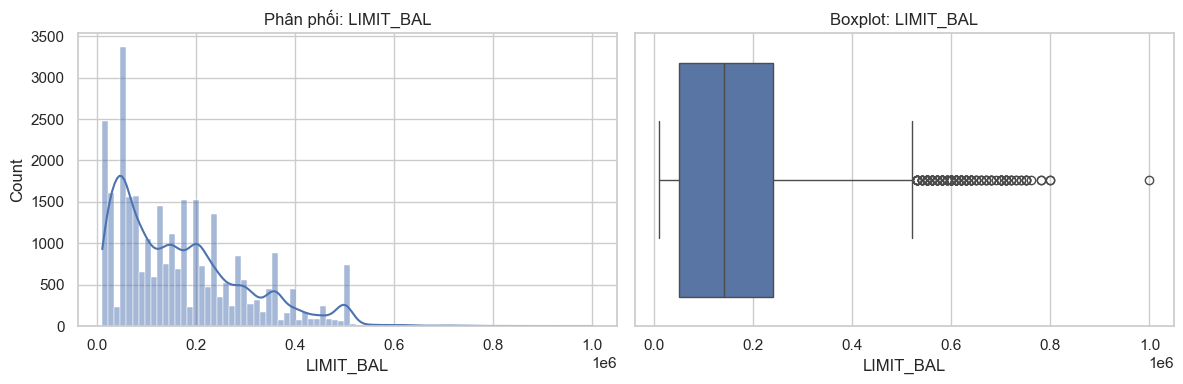

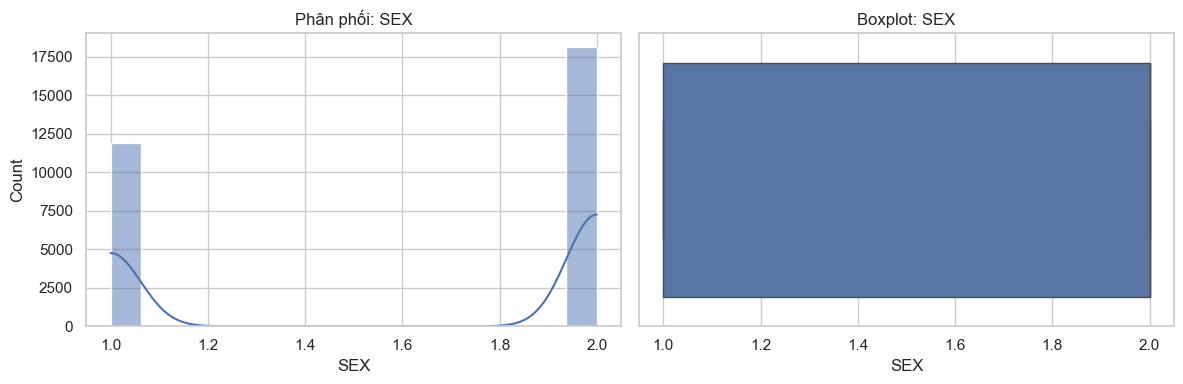

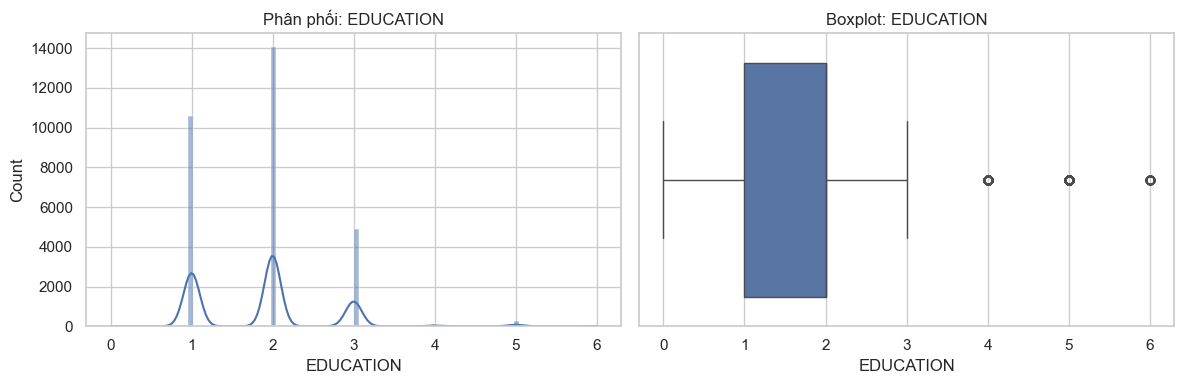

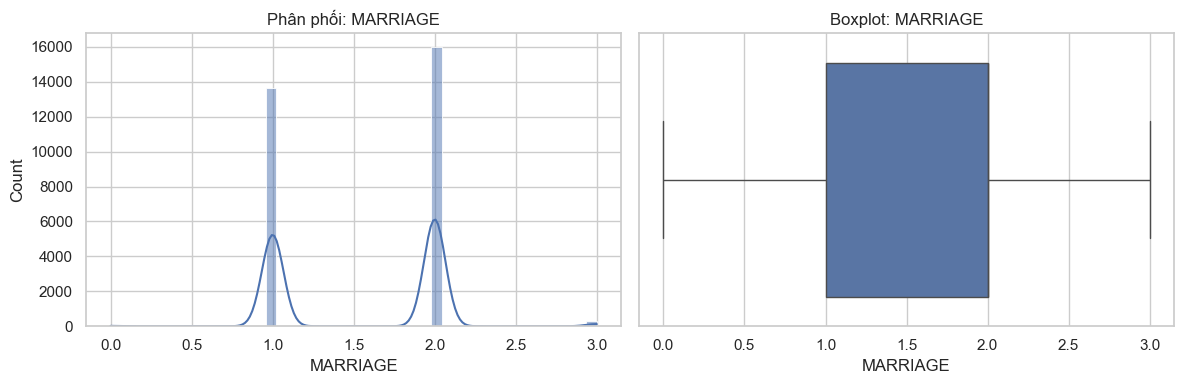

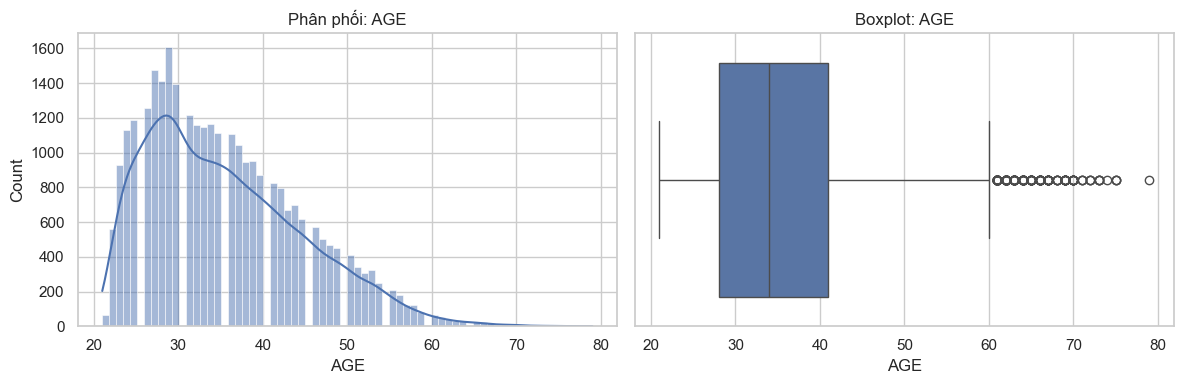

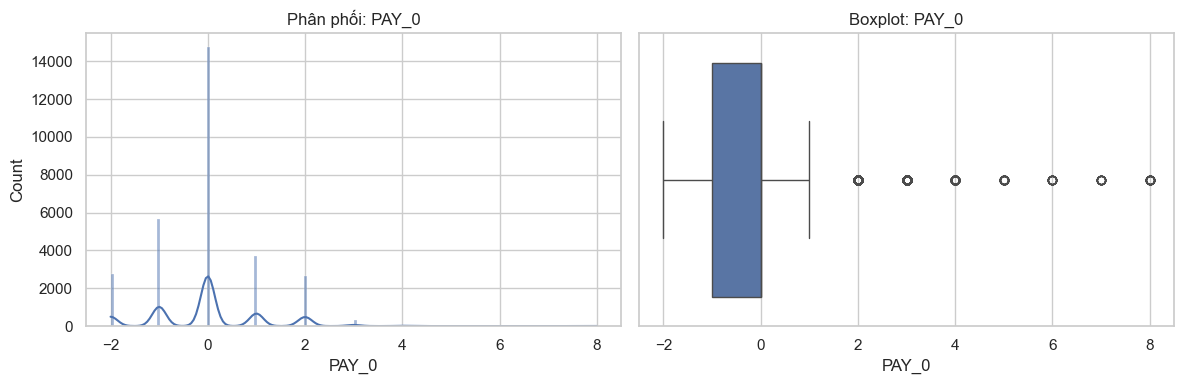

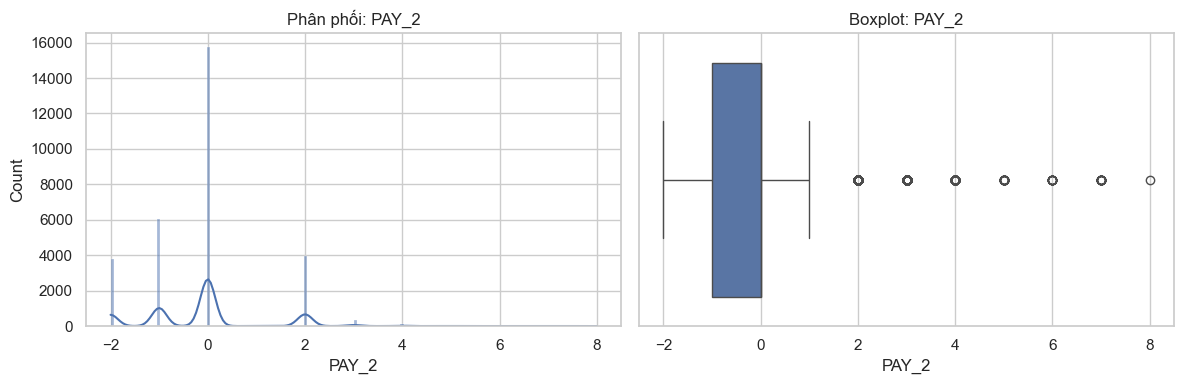

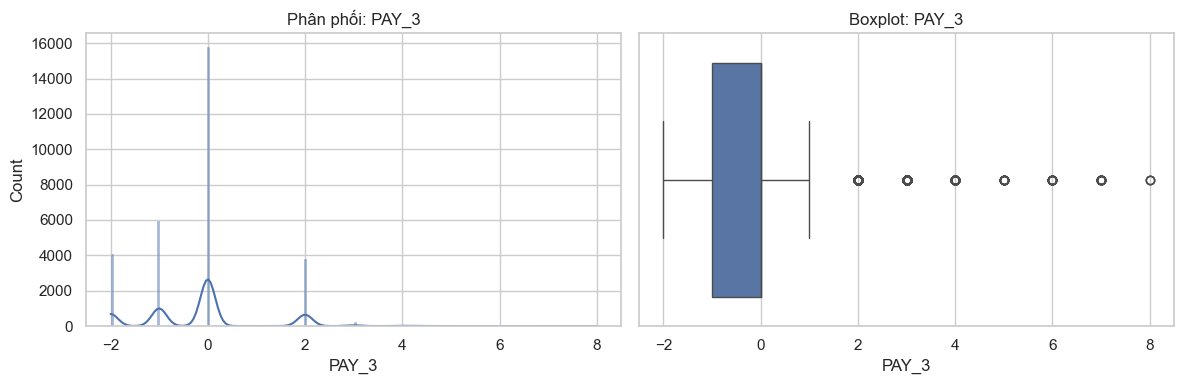

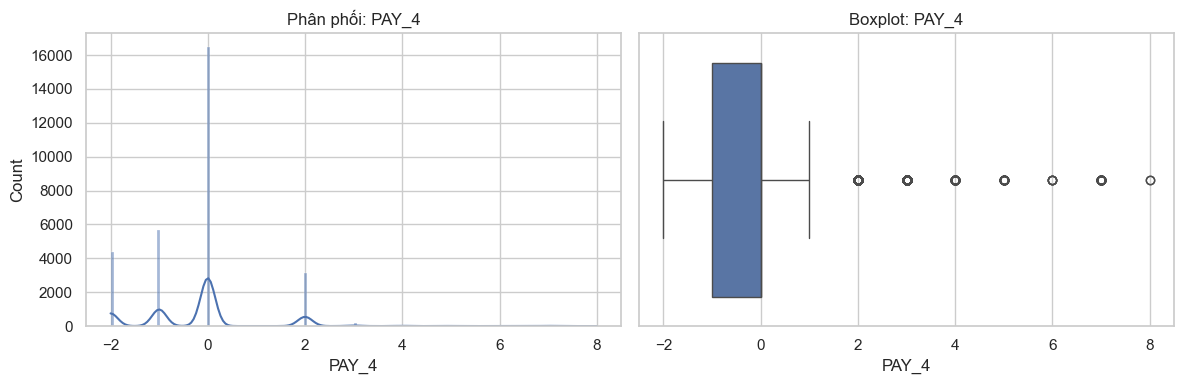

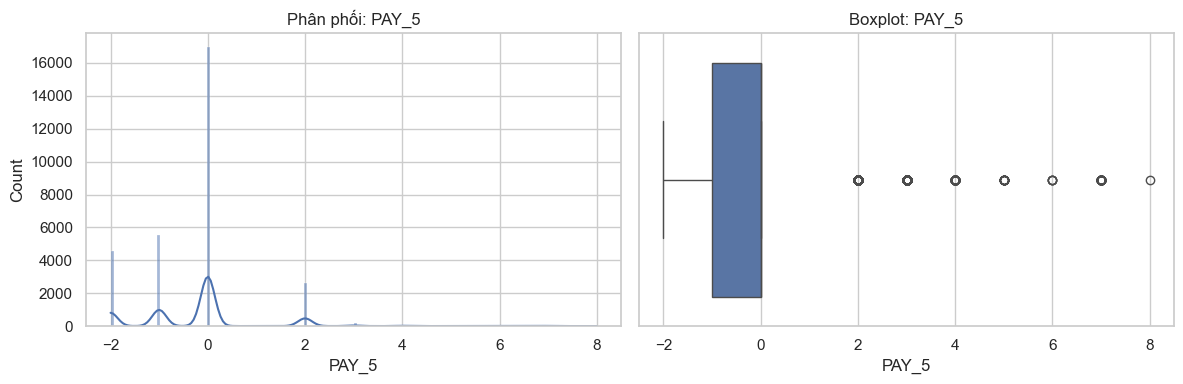

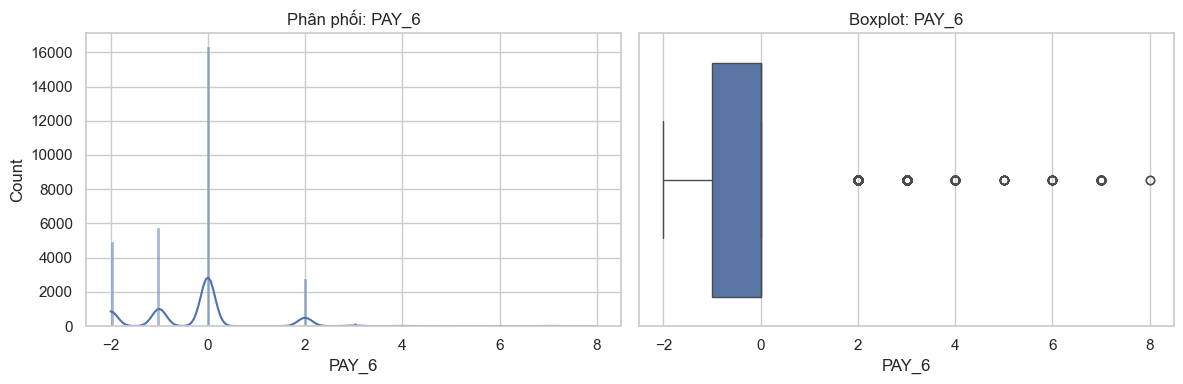

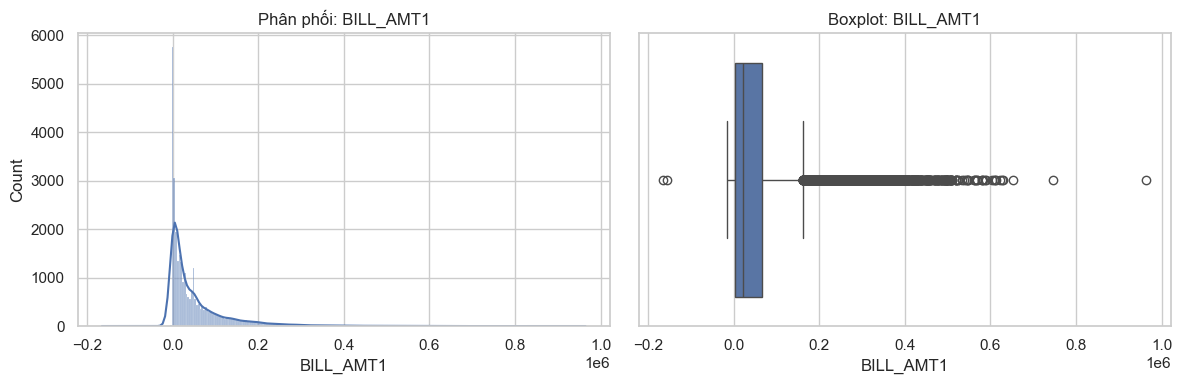

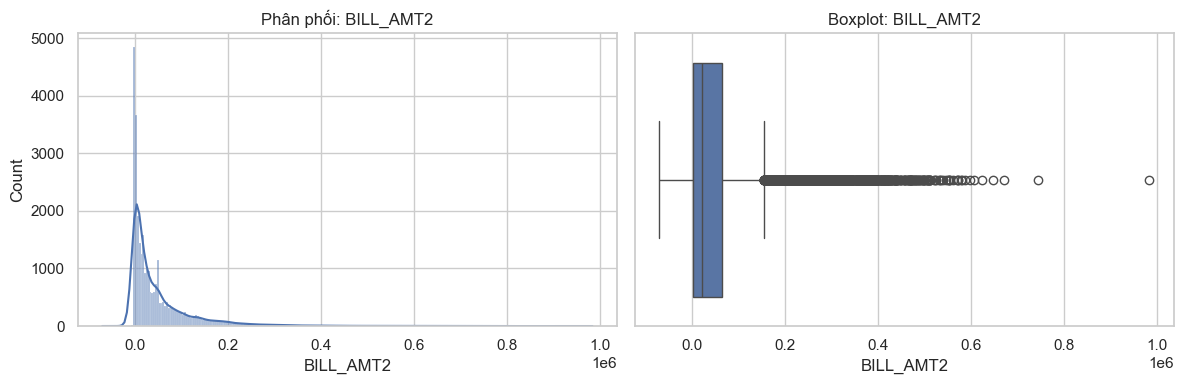

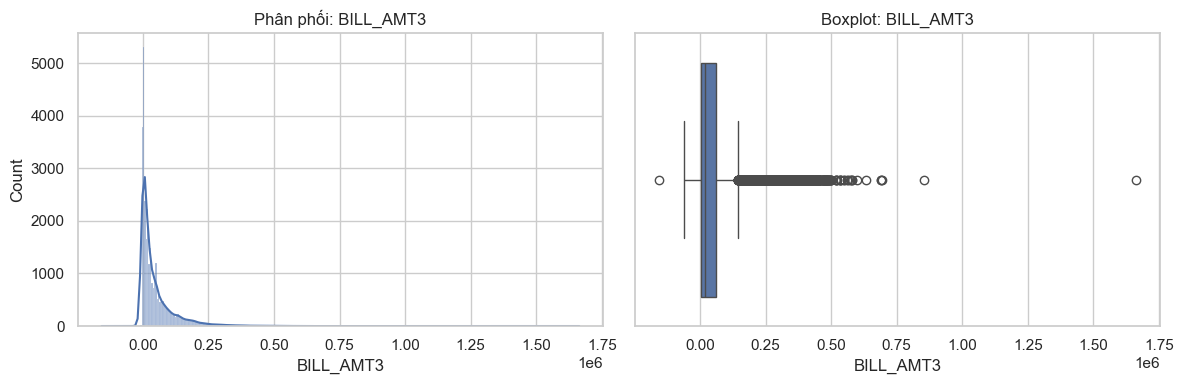

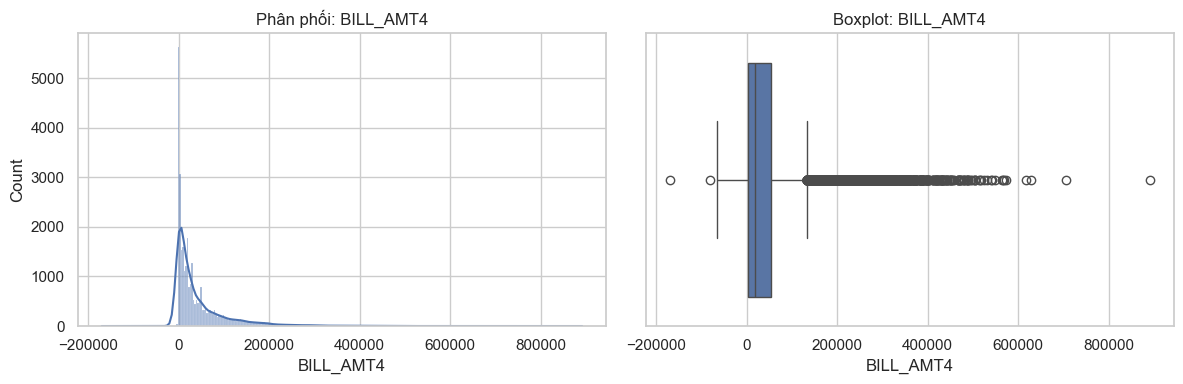

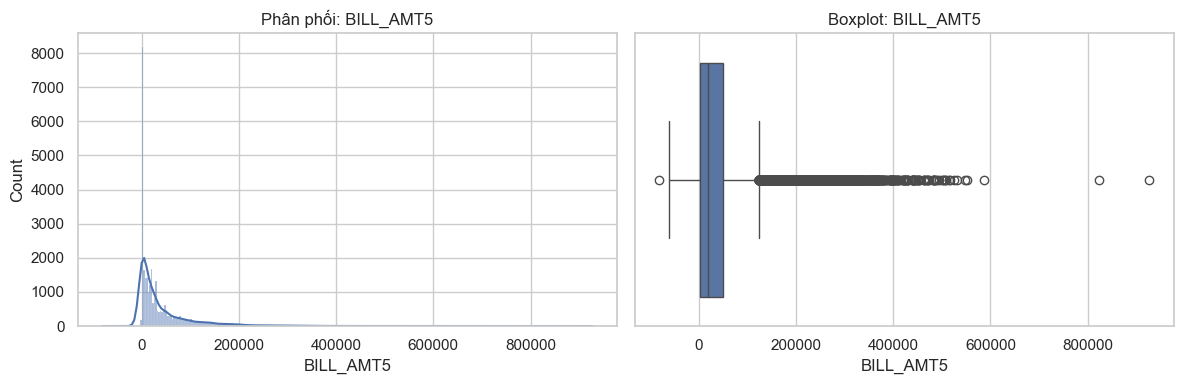

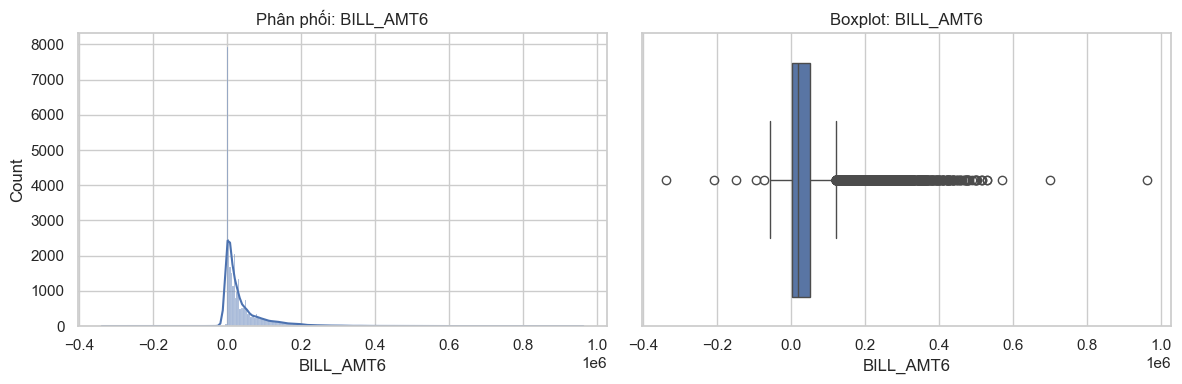

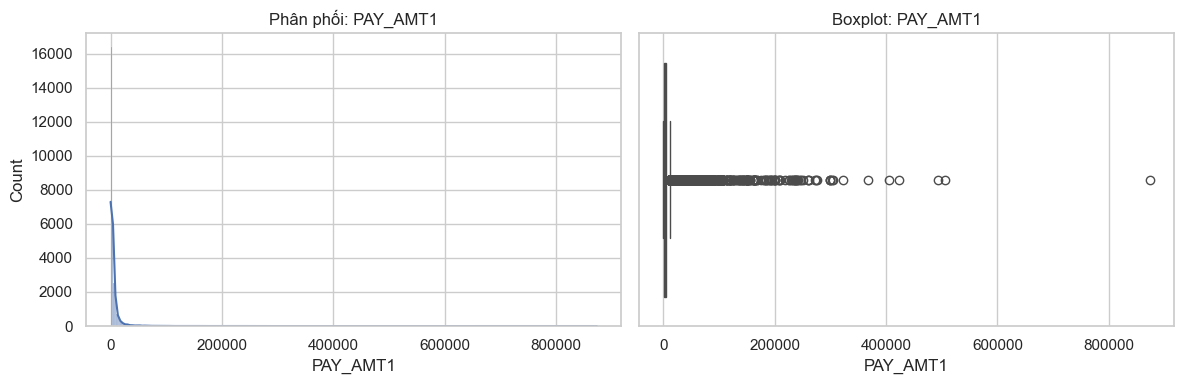

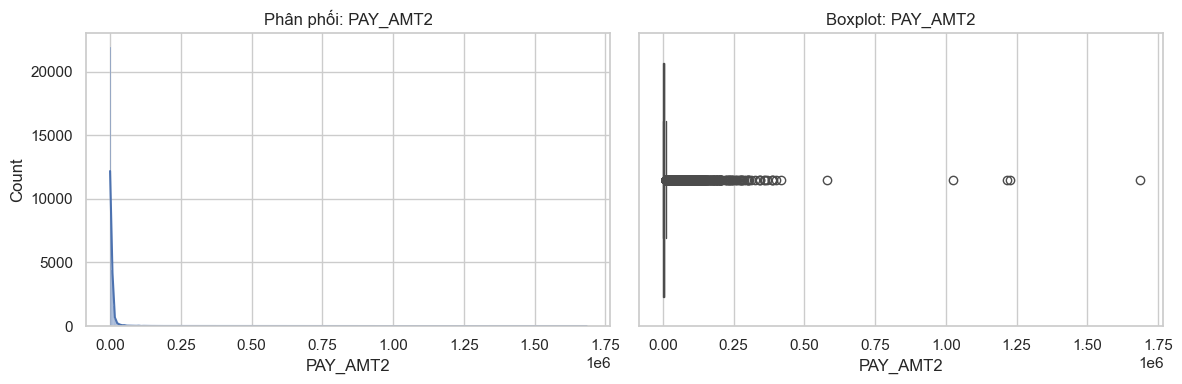

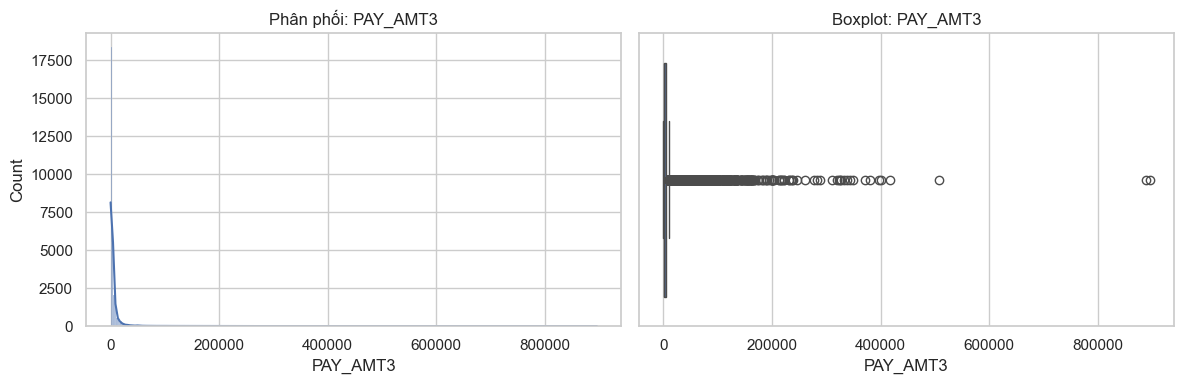

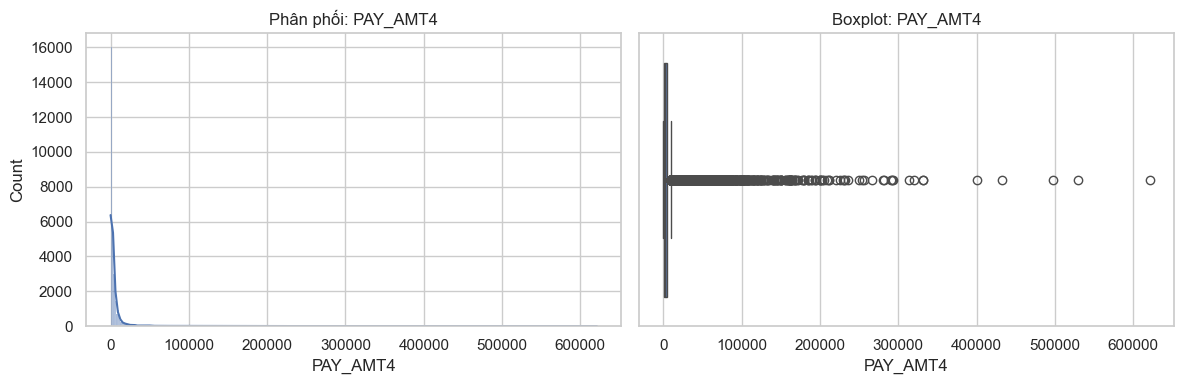

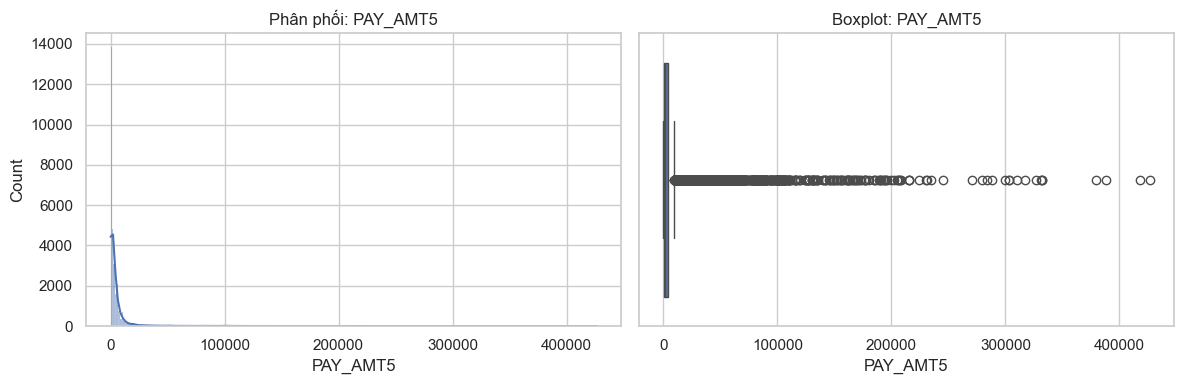

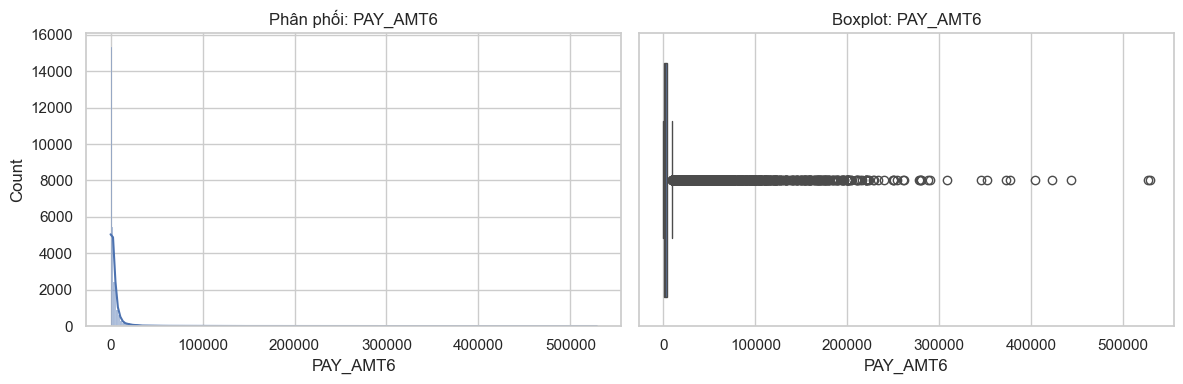

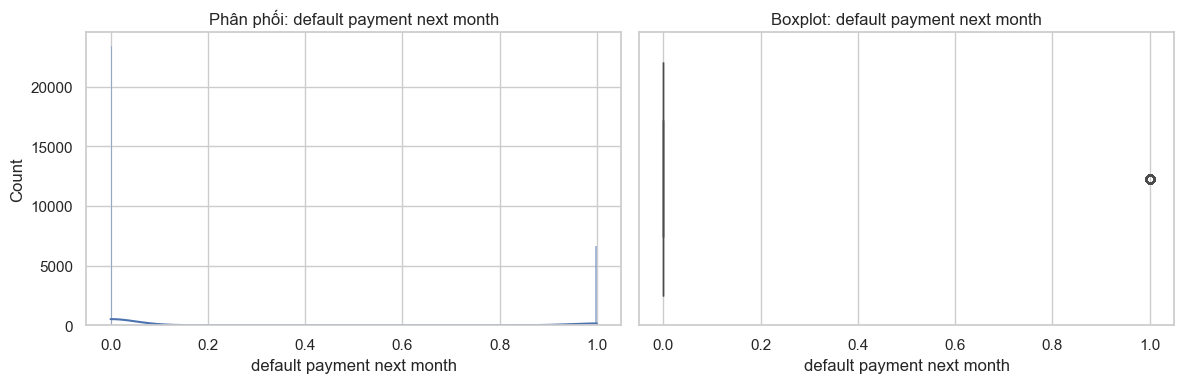

In [5]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()
categorical_cols = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# ID thường chỉ là mã định danh, không nên xem như một đặc trưng liên tục
plot_numeric_cols = [c for c in numeric_cols if c.upper() != "ID"]
plot_categorical_cols = categorical_cols.copy()

for col in plot_numeric_cols:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.histplot(df[col].dropna(), kde=True, ax=axes[0])
    axes[0].set_title(f"Phân phối: {col}")

    sns.boxplot(x=df[col], ax=axes[1])
    axes[1].set_title(f"Boxplot: {col}")

    plt.tight_layout()
    plt.show()

for col in plot_categorical_cols:
    counts = df[col].value_counts(dropna=False).head(20)

    plt.figure(figsize=(10, 4))
    sns.barplot(x=counts.index.astype(str), y=counts.values)
    plt.title(f"Tần suất: {col}")
    plt.xlabel(col)
    plt.ylabel("Số lượng")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

Bivariate Analysis

,sample_count,default_rate,default_rate_pct
sex,,,
1,11888,0.241672,24.167227
2,18112,0.207763,20.776281


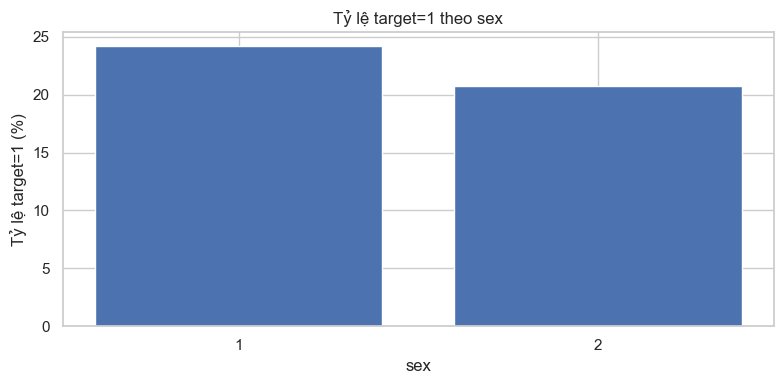

,sample_count,default_rate,default_rate_pct
education,,,
0,14,0.000000,0.000000
1,10585,0.192348,19.234766
2,14030,0.237349,23.734854
3,4917,0.251576,25.157616
4,123,0.056911,5.691057
5,280,0.064286,6.428571
6,51,0.156863,15.686275


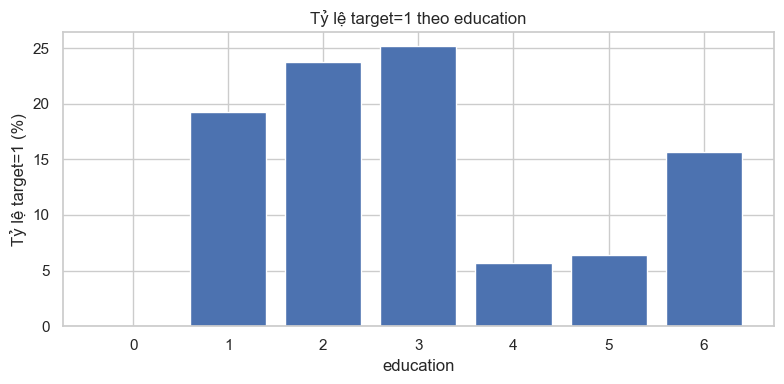

,sample_count,default_rate,default_rate_pct
marriage,,,
0,54,0.092593,9.259259
1,13659,0.234717,23.471704
2,15964,0.209283,20.928339
3,323,0.260062,26.006192


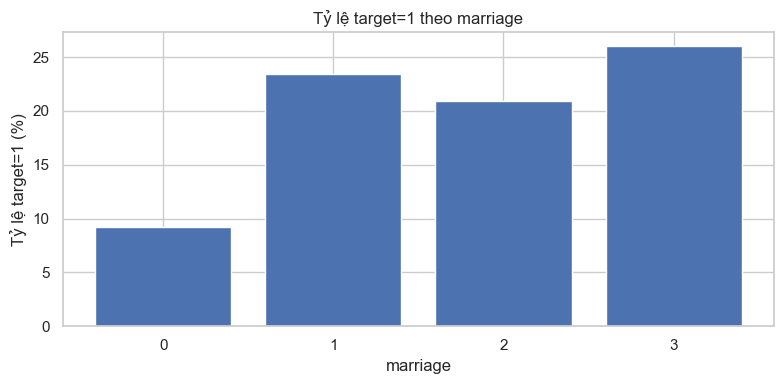

,sample_count,default_rate,default_rate_pct
pay_0,,,
-2,2759,0.132294,13.229431
-1,5686,0.167781,16.778051
0,14737,0.128113,12.811291
1,3688,0.339479,33.947939
2,2667,0.691414,69.141357
3,322,0.757764,75.776398
4,76,0.684211,68.421053
5,26,0.500000,50.000000
6,11,0.545455,54.545455


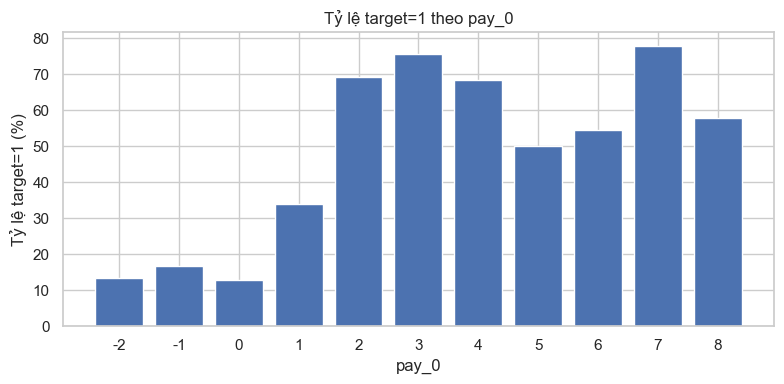

,sample_count,default_rate,default_rate_pct
pay_2,,,
-2,3782,0.182708,18.270756
-1,6050,0.159669,15.966942
0,15730,0.159123,15.912270
1,28,0.178571,17.857143
2,3927,0.556150,55.614973
3,326,0.616564,61.656442
4,99,0.505051,50.505051
5,25,0.600000,60.000000
6,12,0.750000,75.000000


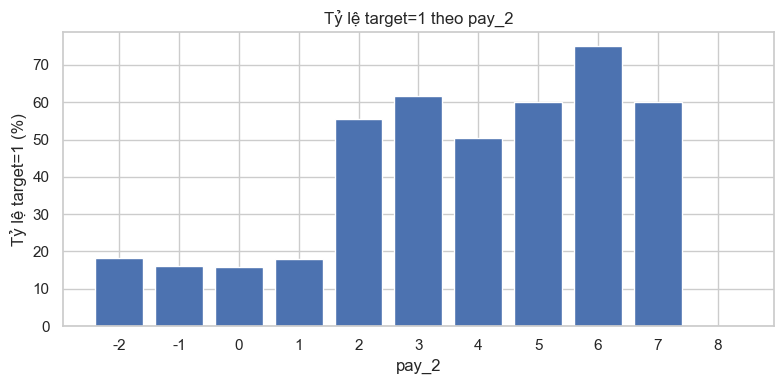

,sample_count,default_rate,default_rate_pct
pay_3,,,
-2,4085,0.185312,18.531212
-1,5938,0.155945,15.594476
0,15764,0.174512,17.451155
1,4,0.250000,25.000000
2,3819,0.515580,51.557999
3,240,0.575000,57.500000
4,76,0.578947,57.894737
5,21,0.571429,57.142857
6,23,0.608696,60.869565


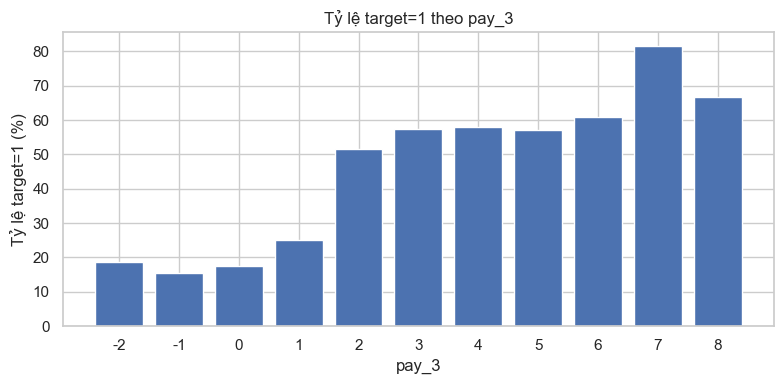

,sample_count,default_rate,default_rate_pct
pay_4,,,
-2,4348,0.192502,19.250230
-1,5687,0.158959,15.895903
0,16455,0.183288,18.328775
1,2,0.500000,50.000000
2,3159,0.523267,52.326686
3,180,0.611111,61.111111
4,69,0.666667,66.666667
5,35,0.514286,51.428571
6,5,0.400000,40.000000


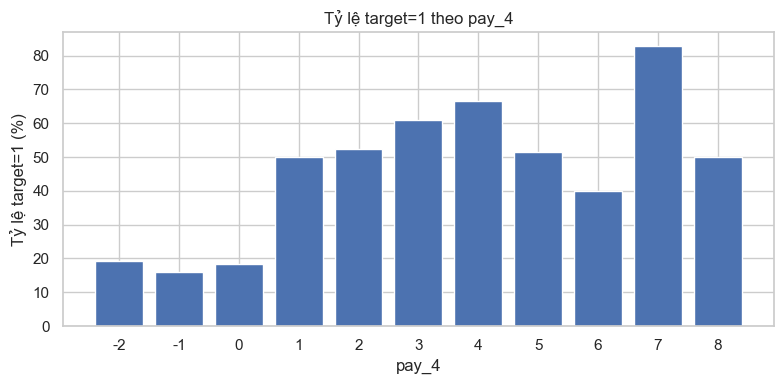

,sample_count,default_rate,default_rate_pct
pay_5,,,
-2,4546,0.196876,19.687637
-1,5539,0.161943,16.194259
0,16947,0.188529,18.852894
2,2626,0.541889,54.188880
3,178,0.634831,63.483146
4,84,0.607143,60.714286
5,17,0.588235,58.823529
6,4,0.750000,75.000000
7,58,0.827586,82.758621


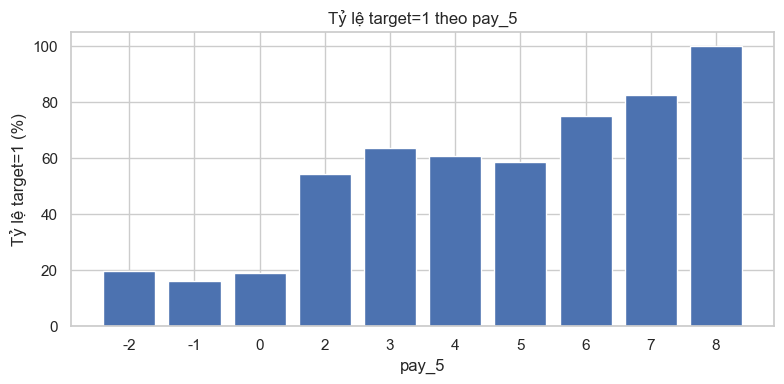

,sample_count,default_rate,default_rate_pct
pay_6,,,
-2,4895,0.200409,20.040858
-1,5740,0.169861,16.986063
0,16286,0.188444,18.844406
2,2766,0.506508,50.650759
3,184,0.641304,64.130435
4,49,0.632653,63.265306
5,13,0.538462,53.846154
6,19,0.736842,73.684211
7,46,0.826087,82.608696


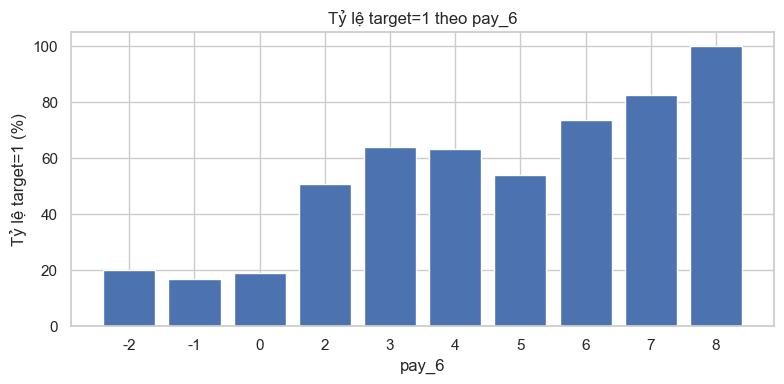

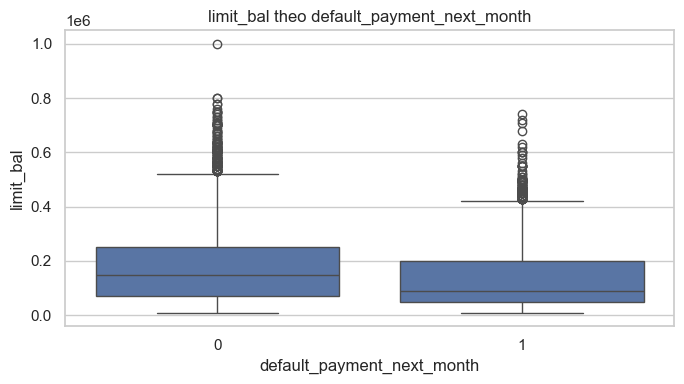

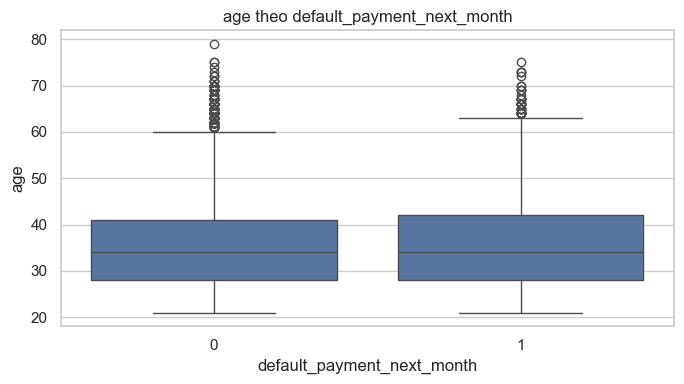

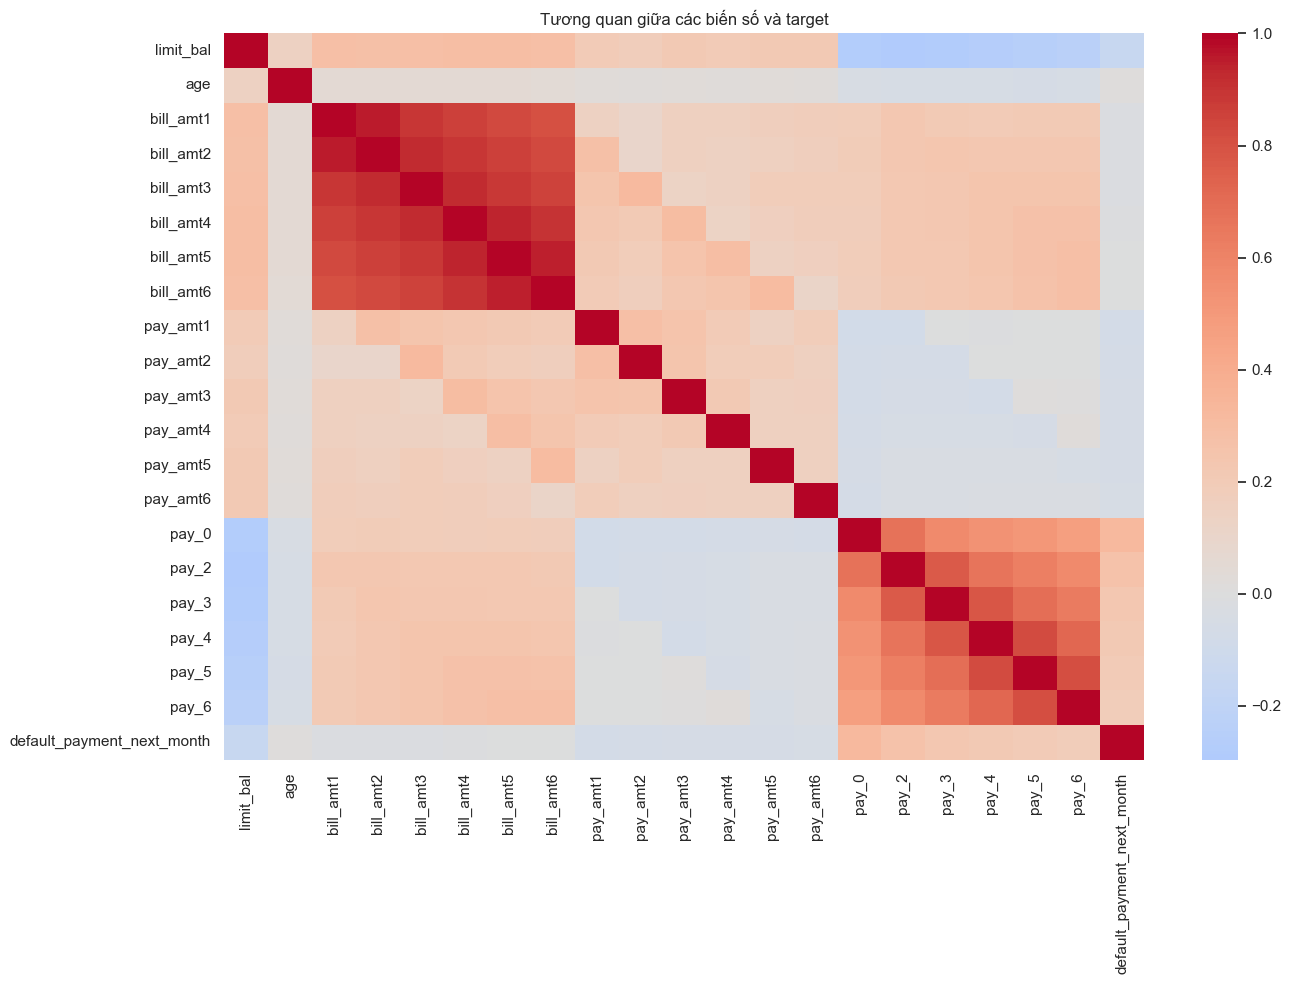

In [11]:
# Tên cột sau khi chuẩn hóa đều viết thường
ID_COL = "id"
TARGET = "default_payment_next_month"

if TARGET not in df.columns:
    raise KeyError(f"Không tìm thấy cột mục tiêu {TARGET!r}")

# Các cột là mã phân loại hoặc mã trạng thái rời rạc
nominal_cols = [
    c for c in ["sex", "education", "marriage"]
    if c in df.columns
]

payment_status_cols = [
    c for c in ["pay_0", "pay_2", "pay_3", "pay_4", "pay_5", "pay_6"]
    if c in df.columns
]

categorical_analysis_cols = nominal_cols + payment_status_cols

# So sánh tỷ lệ target=1 theo từng mã
for col in categorical_analysis_cols:
    summary = (
        df.groupby(col, dropna=False)[TARGET]
        .agg(["count", "mean"])
        .rename(columns={"count": "sample_count", "mean": "default_rate"})
    )
    summary["default_rate_pct"] = summary["default_rate"] * 100

    display(summary)

    plt.figure(figsize=(8, 4))
    plt.bar(summary.index.astype(str), summary["default_rate_pct"])
    plt.title(f"Tỷ lệ target=1 theo {col}")
    plt.xlabel(col)
    plt.ylabel("Tỷ lệ target=1 (%)")
    plt.tight_layout()
    plt.show()

# Biến số liên tục: loại ID, target và mã phân loại
numeric_cols = [
    c for c in df.select_dtypes(include="number").columns
    if c not in {ID_COL, TARGET}
    and c not in nominal_cols
    and c not in payment_status_cols
]

# Boxplot cho một số biến số tiêu biểu
for col in [c for c in ["limit_bal", "age"] if c in numeric_cols]:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df, x=TARGET, y=col)
    plt.title(f"{col} theo {TARGET}")
    plt.tight_layout()
    plt.show()

# Heatmap: không đưa ID hoặc mã danh mục không thứ bậc vào tương quan
corr_cols = numeric_cols + payment_status_cols + [TARGET]
corr = df[corr_cols].corr(numeric_only=True)

plt.figure(figsize=(14, 10))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Tương quan giữa các biến số và target")
plt.tight_layout()
plt.show()

Target Analysis

,count,percentage
default_payment_next_month,,
0,23364,77.88
1,6636,22.12


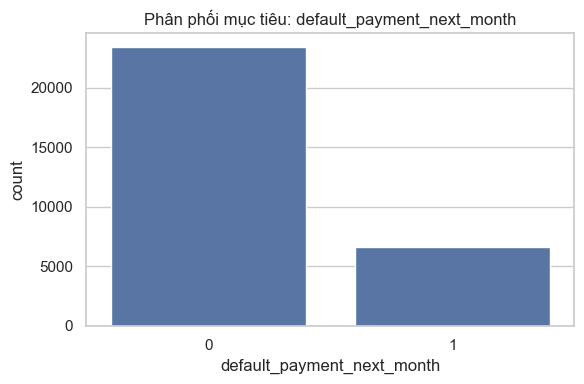

Tỷ lệ lớp thiểu số: 22.12%
Nếu hai lớp mất cân bằng, khi đánh giá mô hình nên xem thêm precision, recall, F1 và PR-AUC; không chỉ dựa vào accuracy.


In [9]:
target_counts = df[TARGET].value_counts(dropna=False).sort_index()
target_pct = (df[TARGET].value_counts(normalize=True, dropna=False) * 100).sort_index()

display(pd.DataFrame({
    "count": target_counts,
    "percentage": target_pct.round(2),
}))

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x=TARGET)
plt.title(f"Phân phối mục tiêu: {TARGET}")
plt.tight_layout()
plt.show()

if df[TARGET].nunique(dropna=True) == 2:
    minority_share = df[TARGET].value_counts(normalize=True, dropna=True).min()
    print(f"Tỷ lệ lớp thiểu số: {minority_share:.2%}")
    print("Nếu hai lớp mất cân bằng, khi đánh giá mô hình nên xem thêm precision, recall, F1 và PR-AUC; không chỉ dựa vào accuracy.")

Domain-specific EDA

In [12]:
# Các cột này thường xuất hiện trong bộ dữ liệu Credit Default.
# Đoạn code chỉ phân tích những cột thực sự có trong df.

payment_cols = [
    c for c in df.columns
    if c.startswith("pay_") and not c.startswith("pay_amt")
]

bill_cols = [
    c for c in df.columns
    if c.upper().startswith("BILL_AMT")
]

payment_amount_cols = [
    c for c in df.columns
    if c.upper().startswith("PAY_AMT")
]

print("Cột lịch sử thanh toán:", payment_cols)
print("Cột số dư hóa đơn:", bill_cols)
print("Cột số tiền thanh toán:", payment_amount_cols)

if payment_cols:
    display(df[payment_cols].describe().T)

if bill_cols:
    display(df[bill_cols].describe().T)

if payment_amount_cols:
    display(df[payment_amount_cols].describe().T)

if payment_cols and TARGET in df.columns:
    payment_by_target = df.groupby(TARGET)[payment_cols].mean().T
    display(payment_by_target)

if bill_cols and payment_amount_cols:
    print(
        "Có thể khảo sát thêm chênh lệch giữa số tiền thanh toán và số dư hóa đơn "
        "nếu các cột cùng kỳ có thể ghép cặp hợp lệ."
    )

Cột lịch sử thanh toán: ['pay_0', 'pay_2', 'pay_3', 'pay_4', 'pay_5', 'pay_6']
Cột số dư hóa đơn: ['bill_amt1', 'bill_amt2', 'bill_amt3', 'bill_amt4', 'bill_amt5', 'bill_amt6']
Cột số tiền thanh toán: ['pay_amt1', 'pay_amt2', 'pay_amt3', 'pay_amt4', 'pay_amt5', 'pay_amt6']


,count,mean,std,min,25%,50%,75%,max
pay_0,30000.0,-0.016700,1.123802,-2.0,-1.0,0.0,0.0,8.0
pay_2,30000.0,-0.133767,1.197186,-2.0,-1.0,0.0,0.0,8.0
pay_3,30000.0,-0.166200,1.196868,-2.0,-1.0,0.0,0.0,8.0
pay_4,30000.0,-0.220667,1.169139,-2.0,-1.0,0.0,0.0,8.0
pay_5,30000.0,-0.266200,1.133187,-2.0,-1.0,0.0,0.0,8.0
pay_6,30000.0,-0.291100,1.149988,-2.0,-1.0,0.0,0.0,8.0


,count,mean,std,min,25%,50%,75%,max
bill_amt1,30000.0,51223.330900,73635.860576,-165580.0,3558.75,22381.5,67091.00,964511.0
bill_amt2,30000.0,49179.075167,71173.768783,-69777.0,2984.75,21200.0,64006.25,983931.0
bill_amt3,30000.0,47013.154800,69349.387427,-157264.0,2666.25,20088.5,60164.75,1664089.0
bill_amt4,30000.0,43262.948967,64332.856134,-170000.0,2326.75,19052.0,54506.00,891586.0
bill_amt5,30000.0,40311.400967,60797.155770,-81334.0,1763.00,18104.5,50190.50,927171.0
bill_amt6,30000.0,38871.760400,59554.107537,-339603.0,1256.00,17071.0,49198.25,961664.0


,count,mean,std,min,25%,50%,75%,max
pay_amt1,30000.0,5663.580500,16563.280354,0.0,1000.00,2100.0,5006.00,873552.0
pay_amt2,30000.0,5921.163500,23040.870402,0.0,833.00,2009.0,5000.00,1684259.0
pay_amt3,30000.0,5225.681500,17606.961470,0.0,390.00,1800.0,4505.00,896040.0
pay_amt4,30000.0,4826.076867,15666.159744,0.0,296.00,1500.0,4013.25,621000.0
pay_amt5,30000.0,4799.387633,15278.305679,0.0,252.50,1500.0,4031.50,426529.0
pay_amt6,30000.0,5215.502567,17777.465775,0.0,117.75,1500.0,4000.00,528666.0


default_payment_next_month,0,1
pay_0,-0.211222,0.668174
pay_2,-0.301917,0.458258
pay_3,-0.316256,0.362116
pay_4,-0.355633,0.254521
pay_5,-0.389488,0.167872
pay_6,-0.405624,0.112116


Có thể khảo sát thêm chênh lệch giữa số tiền thanh toán và số dư hóa đơn nếu các cột cùng kỳ có thể ghép cặp hợp lệ.


## EDA Conclusion

- Bộ dữ liệu gồm 30.000 khách hàng và 25 cột. Kết quả kiểm tra ghi nhận không có giá trị thiếu, dòng trùng hoàn toàn hoặc ID trùng. Cột `id` là mã định danh và đã được loại khỏi phân tích đặc trưng.
- Target có 23.364 mẫu lớp 0 (77,88%) và 6.636 mẫu lớp 1 (22,12%), cho thấy phân phối lớp chưa cân bằng. Khi xây dựng mô hình, nên chia tập có phân tầng theo target và đánh giá bằng precision, recall, F1, PR-AUC cùng confusion matrix; không chỉ dựa vào accuracy.
- Tỷ lệ target=1 khác nhau giữa một số nhóm mã quan sát được: `sex=1` là 24,17%, `sex=2` là 20,78%; các mã `education` phổ biến 1, 2, 3 lần lượt là 19,23%, 23,73%, 25,16%. Đây là mô tả theo mã dữ liệu; cần đối chiếu data dictionary trước khi gán ý nghĩa cho từng mã. Một số nhóm education và marriage có ít mẫu nên tỷ lệ của chúng kém ổn định.
- Các mã trạng thái thanh toán `PAY_0`, `PAY_2`–`PAY_6` từ 2 trở lên nhìn chung có tỷ lệ target=1 cao hơn các mã -2, -1 và 0. Chẳng hạn, tỷ lệ ở `pay_0=2` là 69,14% trên 2.667 mẫu và ở `pay_2=2` là 55,61% trên 3.927 mẫu. Các mã cao hơn thường có số lượng nhỏ, vì vậy không nên diễn giải tỷ lệ của từng mã hiếm như một kết luận chắc chắn.
- Hạn mức tín dụng của nhóm target=1 có trung vị thấp hơn trong biểu đồ so sánh; phân phối tuổi giữa hai lớp khá tương đồng. Các cột `BILL_AMT` và `PAY_AMT` có phân phối lệch phải, với nhiều giá trị lớn/ngoại lệ. Cần xác minh theo ý nghĩa nghiệp vụ trước khi xử lý hoặc loại các giá trị này.
- Heatmap cho thấy các biến số dư hóa đơn giữa các kỳ và các biến trạng thái thanh toán có tương quan theo nhóm. Nên xem xét sự trùng lặp thông tin khi xây dựng mô hình, rồi quyết định dựa trên kết quả validation.
- Trước khi huấn luyện, cần xử lý các biến mã theo đúng bản chất phân loại/thứ bậc, đối chiếu các mã chưa rõ với data dictionary và loại `id` khỏi đặc trưng. Các bước tiền xử lý hoặc cân bằng lớp cần được fit/thực hiện trên tập train để tránh rò rỉ dữ liệu.